# Banana Disease Classification: Cleaned Labels and Fine-tuning

Follow-up to `banana_disease_classification-3.ipynb`. That notebook froze the pretrained
MobileNetV2 layers and trained only the final layer for 5 epochs, which reached 73.9% test
accuracy on 9 classes.

A first attempt at fine-tuning the whole network gave no gain (75.5% against 75.9% for the
old model on a deduplicated test set). The errors came from the data, not from too little
training:

1. 79 groups of byte-identical images appear under more than one class. 69 of them are
   filed as both Black Sigatoka and Panama Disease.
2. Black Pitting/Rust and Fungal Disease look the same (ripe fruit with brown spots) and
   were swapped 63 times in 241 fruit test images.

This notebook fixes the labels first, then fine-tunes on Apple's MPS backend (the Mac GPU).

Changes from the first version:

1. Images whose identical copies carry different labels are removed from every split.
2. Exact duplicates are kept only once, so no test image also appears in training.
3. Black Pitting/Rust and Fungal Disease are merged into one class, `Banana_spotted_fruit_disease`.
4. Stronger augmentation (random crop, rotation, color jitter).
5. Class-weighted loss, because the smallest class has about 70 training images and the largest about 1,000.
6. Two training stages: the new head first, then the whole network at a low learning rate.
7. The epoch with the best validation accuracy is kept instead of the last one.

## 1. Setup

In [1]:
import os
import copy
import json
import time
import random
import hashlib
from collections import defaultdict, Counter
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from PIL import Image
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets, transforms, models
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

DATA_DIR = "banana_data"
SPLITS = ["train", "valid", "test"]
IMAGE_SIZE = 224
BATCH_SIZE = 32
HEAD_EPOCHS = 3
HEAD_LEARNING_RATE = 1e-3
FINETUNE_EPOCHS = 12
FINETUNE_LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4
SEED = 42
PROGRESS_LOG = "training_progress.log"

# The two fruit classes the data cannot separate become one
MERGED_CLASSES = {
    "Banana_Black_Pitting_or_Banana_Rust": "Banana_spotted_fruit_disease",
    "Banana_fungal_disease": "Banana_spotted_fruit_disease",
}

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# MPS is the Mac GPU; fall back to CUDA or CPU anywhere else
if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")
print("Using device:", device, "| torch", torch.__version__)

Using device: mps | torch 2.15.0


## 2. Clean the labels

Every image is hashed (MD5 of the file bytes), so two files with the same hash are the same
picture. The cleaning runs in three steps:

1. Map each original class to its new name (the two spotted-fruit classes share one name).
2. Remove every copy of a picture whose copies carry different labels, since no model can be
   right about both.
3. Keep a picture only the first time it appears, in the order train, valid, test. This stops
   a test image from also being a training image.

In [2]:
def file_hash(path):
    with open(path, "rb") as image_file:
        return hashlib.md5(image_file.read()).hexdigest()


all_images = []
for split in SPLITS:
    folder = datasets.ImageFolder(os.path.join(DATA_DIR, split))
    for path, label in folder.samples:
        original_class = folder.classes[label]
        new_class = MERGED_CLASSES.get(original_class, original_class)
        all_images.append({"split": split, "path": path, "hash": file_hash(path), "class": new_class})

labels_per_hash = defaultdict(set)
for image in all_images:
    labels_per_hash[image["hash"]].add(image["class"])

conflicting_hashes = set(h for h, labels in labels_per_hash.items() if len(labels) > 1)
conflict_pairs = Counter(tuple(sorted(labels_per_hash[h])) for h in conflicting_hashes)
print("Pictures with conflicting labels:", len(conflicting_hashes))
for pair, count in conflict_pairs.most_common():
    print(f"  {count:3d}  {pair}")

clean_images = []
seen_hashes = set()
for image in all_images:
    if image["hash"] in conflicting_hashes or image["hash"] in seen_hashes:
        continue
    seen_hashes.add(image["hash"])
    clean_images.append(image)

print()
print("Images before:", Counter(image["split"] for image in all_images))
print("Images after: ", Counter(image["split"] for image in clean_images))

Pictures with conflicting labels: 74
   69  ('Banana_leaf_Black_Sigatoka', 'Banana_leaf__Panama_Disease.')
    4  ('Banana_Crown_Rot', 'Banana_spotted_fruit_disease')
    1  ('Banana_Healthy', 'Banana_spotted_fruit_disease')

Images before: Counter({'train': 2805, 'valid': 630, 'test': 502})
Images after:  Counter({'train': 2679, 'valid': 603, 'test': 474})


In [3]:
class_names = sorted(set(image["class"] for image in clean_images))
num_classes = len(class_names)
class_index = {name: index for index, name in enumerate(class_names)}

samples = {split: [] for split in SPLITS}
for image in clean_images:
    samples[image["split"]].append((image["path"], class_index[image["class"]]))

print(f"{'class':40s} {'train':>6s} {'valid':>6s} {'test':>6s}")
for name in class_names:
    counts = [sum(1 for _, label in samples[split] if label == class_index[name]) for split in SPLITS]
    print(f"{name:40s} {counts[0]:6d} {counts[1]:6d} {counts[2]:6d}")

class                                     train  valid   test
Banana_Crown_Rot                            189     53     26
Banana_Healthy                              114     29     18
Banana_leaf_Banana_Scab_Moth                 70     20     10
Banana_leaf_Black_Sigatoka                  444     96     76
Banana_leaf_Healthy                         497    100    100
Banana_leaf__Black_Leaf_Streak              220     63     32
Banana_leaf__Panama_Disease.                150     43     16
Banana_spotted_fruit_disease                995    199    196


## 3. Datasets with augmentation

In [4]:
# ImageNet statistics, because MobileNetV2 was pretrained with them
normalize = transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])

# Saved images are already 224x224, so the random crop zooms in and resizes back up
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMAGE_SIZE, scale=(0.6, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    normalize,
])
eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    normalize,
])


class ImageList(Dataset):
    # A plain list of (path, label) pairs, so the cleaned lists can be used directly
    def __init__(self, samples, transform):
        self.samples = samples
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        path, label = self.samples[index]
        image = Image.open(path).convert("RGB")
        return self.transform(image), label


train_dataset = ImageList(samples["train"], train_transform)
valid_dataset = ImageList(samples["valid"], eval_transform)
test_dataset = ImageList(samples["test"], eval_transform)

# num_workers=0 because worker processes are unreliable inside notebooks on macOS
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
valid_loader = DataLoader(valid_dataset, batch_size=BATCH_SIZE, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, num_workers=0)

print("Train / valid / test:", len(train_dataset), len(valid_dataset), len(test_dataset))

Train / valid / test: 2679 603 474


## 4. Class-weighted loss

Each class gets a weight inversely proportional to its training count, so a mistake on a
rare class costs more than a mistake on a common one.

In [5]:
train_labels = np.array([label for _, label in samples["train"]])
class_counts = np.bincount(train_labels, minlength=num_classes)
class_weights = len(train_labels) / (num_classes * class_counts)

for name, count, weight in zip(class_names, class_counts, class_weights):
    print(f"{name:40s} {count:4d} images, weight {weight:.2f}")

loss_function = nn.CrossEntropyLoss(weight=torch.tensor(class_weights, dtype=torch.float32).to(device))

Banana_Crown_Rot                          189 images, weight 1.77
Banana_Healthy                            114 images, weight 2.94
Banana_leaf_Banana_Scab_Moth               70 images, weight 4.78
Banana_leaf_Black_Sigatoka                444 images, weight 0.75
Banana_leaf_Healthy                       497 images, weight 0.67
Banana_leaf__Black_Leaf_Streak            220 images, weight 1.52
Banana_leaf__Panama_Disease.              150 images, weight 2.23
Banana_spotted_fruit_disease              995 images, weight 0.34


## 5. Training helpers

In [6]:
def report(line):
    # Also written to a file, so progress is visible while the notebook runs headless
    print(line)
    with open(PROGRESS_LOG, "a") as log_file:
        log_file.write(line + "\n")


def run_one_epoch(model, optimizer):
    model.train()
    total_loss = 0.0
    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        loss = loss_function(model(images), labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
    return total_loss / len(train_loader)


def predict_all(model, loader):
    model.eval()
    all_labels = []
    all_predictions = []
    all_confidences = []
    with torch.no_grad():
        for images, labels in loader:
            probabilities = torch.softmax(model(images.to(device)), dim=1)
            all_labels.extend(labels.tolist())
            all_predictions.extend(probabilities.argmax(dim=1).cpu().tolist())
            all_confidences.extend(probabilities.max(dim=1).values.cpu().tolist())
    return np.array(all_labels), np.array(all_predictions), np.array(all_confidences)


def accuracy(model, loader):
    labels, predictions, _ = predict_all(model, loader)
    return (labels == predictions).mean()


if os.path.exists(PROGRESS_LOG):
    os.remove(PROGRESS_LOG)

## 6. Stage 1: train the new head only

The new final layer starts random. Training it alone first stops its large early errors from
damaging the pretrained features once those are unfrozen.

In [7]:
model = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT)
model.classifier[1] = nn.Linear(model.last_channel, num_classes)
model = model.to(device)

for parameter in model.features.parameters():
    parameter.requires_grad = False

head_optimizer = optim.AdamW(model.classifier.parameters(), lr=HEAD_LEARNING_RATE, weight_decay=WEIGHT_DECAY)

valid_history = []
for epoch in range(HEAD_EPOCHS):
    start_time = time.time()
    train_loss = run_one_epoch(model, head_optimizer)
    valid_accuracy = accuracy(model, valid_loader)
    valid_history.append(valid_accuracy)
    report(f"Head epoch {epoch + 1}: loss {train_loss:.4f}, valid accuracy {valid_accuracy:.3f}, {time.time() - start_time:.0f}s")

Head epoch 1: loss 1.4141, valid accuracy 0.811, 19s


Head epoch 2: loss 0.8528, valid accuracy 0.804, 15s


Head epoch 3: loss 0.7100, valid accuracy 0.806, 15s


## 7. Stage 2: fine-tune the whole network

All layers are unfrozen with a learning rate 10x lower than stage 1, so the pretrained
features shift gently toward banana images. A cosine schedule lowers the learning rate
toward zero by the last epoch. The weights from the best validation epoch are kept.

In [8]:
for parameter in model.parameters():
    parameter.requires_grad = True

finetune_optimizer = optim.AdamW(model.parameters(), lr=FINETUNE_LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = optim.lr_scheduler.CosineAnnealingLR(finetune_optimizer, T_max=FINETUNE_EPOCHS)

best_valid_accuracy = 0.0
best_state = None
best_epoch = 0

for epoch in range(FINETUNE_EPOCHS):
    start_time = time.time()
    train_loss = run_one_epoch(model, finetune_optimizer)
    scheduler.step()
    valid_accuracy = accuracy(model, valid_loader)
    valid_history.append(valid_accuracy)

    if valid_accuracy > best_valid_accuracy:
        best_valid_accuracy = valid_accuracy
        best_state = copy.deepcopy(model.state_dict())
        best_epoch = HEAD_EPOCHS + epoch + 1

    report(f"Fine-tune epoch {epoch + 1}: loss {train_loss:.4f}, valid accuracy {valid_accuracy:.3f}, {time.time() - start_time:.0f}s")

model.load_state_dict(best_state)
report(f"Best valid accuracy {best_valid_accuracy:.3f} at overall epoch {best_epoch}")

Fine-tune epoch 1: loss 0.4675, valid accuracy 0.841, 44s


Fine-tune epoch 2: loss 0.3402, valid accuracy 0.839, 54s


Fine-tune epoch 3: loss 0.2889, valid accuracy 0.876, 56s


Fine-tune epoch 4: loss 0.2392, valid accuracy 0.854, 51s


Fine-tune epoch 5: loss 0.2379, valid accuracy 0.877, 126s


Fine-tune epoch 6: loss 0.2086, valid accuracy 0.877, 68s


... (2 outputs left out)

Fine-tune epoch 9: loss 0.1812, valid accuracy 0.892, 60s


Fine-tune epoch 10: loss 0.1748, valid accuracy 0.892, 53s


Fine-tune epoch 11: loss 0.1861, valid accuracy 0.896, 56s


Fine-tune epoch 12: loss 0.1743, valid accuracy 0.897, 55s
Best valid accuracy 0.897 at overall epoch 15


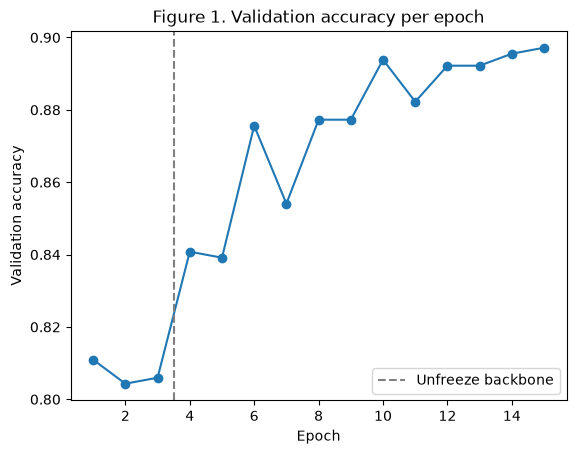

In [9]:
plt.plot(range(1, len(valid_history) + 1), valid_history, marker="o")
plt.axvline(HEAD_EPOCHS + 0.5, color="gray", linestyle="--", label="Unfreeze backbone")
plt.xlabel("Epoch")
plt.ylabel("Validation accuracy")
plt.title("Figure 1. Validation accuracy per epoch")
plt.legend()
plt.show()

## 8. Compare with the old model on the same cleaned test set

The old frozen-backbone weights are loaded from `model_v1/banana_mobilenet.pth` (a copy of
the version deployed first). Its 9-class predictions are mapped onto the new 8 classes the
same way the labels were, so both models are scored on the same images and the same classes.

In [10]:
OLD_CLASS_NAMES = [
    "Banana_Black_Pitting_or_Banana_Rust", "Banana_Crown_Rot", "Banana_Healthy",
    "Banana_fungal_disease", "Banana_leaf_Banana_Scab_Moth", "Banana_leaf_Black_Sigatoka",
    "Banana_leaf_Healthy", "Banana_leaf__Black_Leaf_Streak", "Banana_leaf__Panama_Disease.",
]
old_to_new = np.array([class_index[MERGED_CLASSES.get(name, name)] for name in OLD_CLASS_NAMES])

old_model = models.mobilenet_v2(weights=None)
old_model.classifier[1] = nn.Linear(old_model.last_channel, len(OLD_CLASS_NAMES))
old_model.load_state_dict(torch.load("model_v1/banana_mobilenet.pth", map_location="cpu"))
old_model = old_model.to(device)

true_labels, old_predictions, _ = predict_all(old_model, test_loader)
old_predictions = old_to_new[old_predictions]
_, new_predictions, new_confidences = predict_all(model, test_loader)

print(f"Old model (frozen backbone, merged classes) test accuracy: {(old_predictions == true_labels).mean():.3f}")
print(f"New model (cleaned labels, fine-tuned)      test accuracy: {(new_predictions == true_labels).mean():.3f}")
print()
print(classification_report(true_labels, new_predictions, target_names=class_names, digits=3))

Old model (frozen backbone, merged classes) test accuracy: 0.909
New model (cleaned labels, fine-tuned)      test accuracy: 0.895

                                precision    recall  f1-score   support

              Banana_Crown_Rot      0.514     0.731     0.603        26
                Banana_Healthy      0.600     1.000     0.750        18
  Banana_leaf_Banana_Scab_Moth      0.909     1.000     0.952        10
    Banana_leaf_Black_Sigatoka      0.985     0.855     0.915        76
           Banana_leaf_Healthy      0.990     0.990     0.990       100
Banana_leaf__Black_Leaf_Streak      1.000     0.969     0.984        32
  Banana_leaf__Panama_Disease.      0.556     0.938     0.698        16
  Banana_spotted_fruit_disease      0.971     0.852     0.908       196

                      accuracy                          0.895       474
                     macro avg      0.815     0.917     0.850       474
                  weighted avg      0.925     0.895     0.903       474



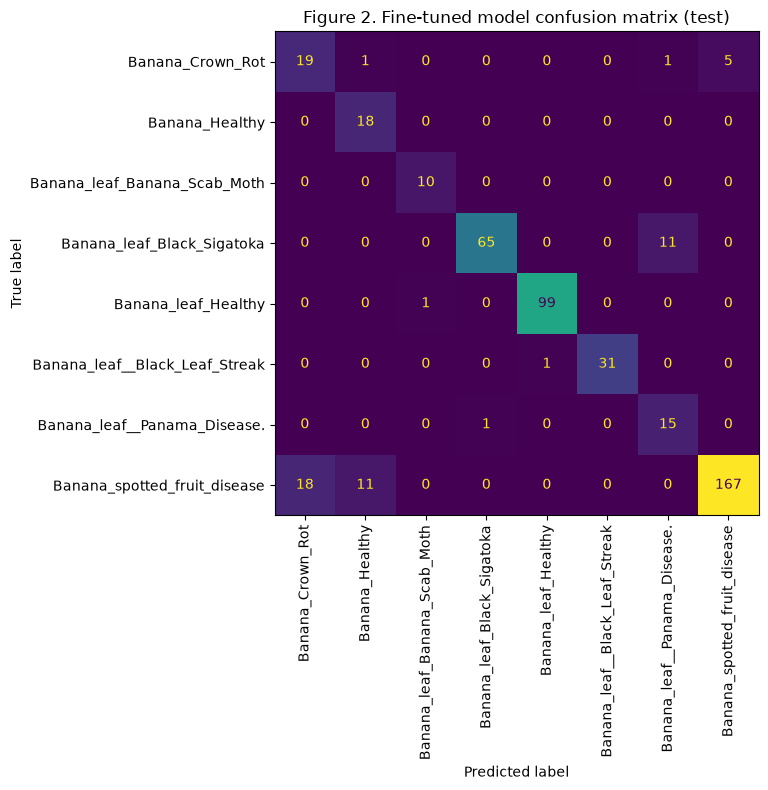

In [11]:
matrix = confusion_matrix(true_labels, new_predictions)
display = ConfusionMatrixDisplay(matrix, display_labels=class_names)
figure, axis = plt.subplots(figsize=(8, 8))
display.plot(ax=axis, xticks_rotation=90, colorbar=False)
axis.set_title("Figure 2. Fine-tuned model confusion matrix (test)")
plt.tight_layout()
plt.show()

In [12]:
is_correct = new_predictions == true_labels
print("Mean confidence when correct:", new_confidences[is_correct].mean())
if (~is_correct).any():
    print("Mean confidence when wrong:  ", new_confidences[~is_correct].mean())

Mean confidence when correct: 0.9332439690687746
Mean confidence when wrong:   0.7445219260454178


## 9. Save weights and export ONNX

The browser app reads ONNX, so the export keeps the same input name (`image`) and output
name (`scores`) as before. The app reads its class list from `class_names.json`, so the
move from 9 to 8 classes needs no change to `deploy/index.html`.

In [13]:
import onnxruntime as ort

os.makedirs("model", exist_ok=True)
model = model.cpu().eval()

torch.save(model.state_dict(), "model/banana_mobilenet.pth")
for folder in ["model", "deploy"]:
    with open(os.path.join(folder, "class_names.json"), "w") as class_names_file:
        json.dump(class_names, class_names_file)

dummy_image = torch.randn(1, 3, IMAGE_SIZE, IMAGE_SIZE)
torch.onnx.export(
    model,
    dummy_image,
    "deploy/banana_mobilenet.onnx",
    input_names=["image"],
    output_names=["scores"],
    opset_version=18,
    external_data=False,
)

# Check the ONNX file on real test images, not only random noise.
# The export fixes the batch size at 1 (the browser sends one image), so images go in one at a time.
session = ort.InferenceSession("deploy/banana_mobilenet.onnx")
test_images, _ = next(iter(test_loader))
onnx_scores = np.concatenate([session.run(None, {"image": image[None].numpy()})[0] for image in test_images])
with torch.no_grad():
    torch_scores = model(test_images).numpy()

print("Max difference:", np.abs(onnx_scores - torch_scores).max())
print("Same predictions:", (onnx_scores.argmax(1) == torch_scores.argmax(1)).all())
print("ONNX file size (MB):", os.path.getsize("deploy/banana_mobilenet.onnx") / 1e6)

[torch.onnx] Obtain model graph for `MobileNetV2([...]` with `torch.export.export(..., strict=False)`...


[torch.onnx] Obtain model graph for `MobileNetV2([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...


Python(7982) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅


Max difference: 0.00032138824
Same predictions: True
ONNX file size (MB): 9.13905
